# CharacterBox U/S/P Results Dashboard

One section per hypothesis (H1 consistency, H2 realism, H3 multi-turn consistency), built on a
shared pre-processing step. It reads the final study's layout, one folder per generation seed and
scene (pilot), written by `tools/run_final.py`:

```
output/final/seed{N}/p{NN}/trajectory.jsonl       generation (simulator.py)
output/final/seed{N}/p{NN}/h1_consistency.jsonl   H1 judge (evaluate.py --h1-only)
output/final/seed{N}/p{NN}/h2_realism.jsonl       H2 judge (evaluate.py --h2-only)
```

Run or resume the study, then re-run this notebook top to bottom. Missing files are skipped, so
it also works part-way through.

**Primary comparison:** P vs S. **Secondary:** S vs U, P vs U (`docs/research-contract.md` §6).

## 0. Data cleaning & pre-processing

In [43]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")

REPO_ROOT = Path.cwd().parent  # this notebook lives in notebooks/, one level under the repo root
FINAL_DIR = REPO_ROOT / "output" / "final"

# Restrict the analysis, e.g. SEEDS = [1] or PILOTS = [6, 7, 8, 9, 10] (the scenes not used to
# develop the trials and judge). None keeps everything found under FINAL_DIR.
SEEDS = None
PILOTS = None

CONDITION_ORDER = ["U", "S", "P"]
CONDITION_COLORS = {"U": "#3498db", "S": "#9b59b6", "P": "#e67e22"}
DECISION_ORDER = ["PASS", "FAIL", "NA"]
DECISION_COLORS = {"PASS": "#2ecc71", "FAIL": "#e74c3c", "NA": "#bdc3c7"}
METRIC_COLUMNS = {
    "Context Use": "decisions.context_use.decision",
    "World Consistency": "decisions.world_consistency.decision",
    "No Contradiction": "decisions.no_contradiction.decision",
}
# trial_type is set per trial by the pilot manifest (docs/trial-design-guide.md).
TRIAL_TYPE_NAMES = {1: "1: neutral (t01-t06)", 2: "2: stress (t07-t10)", 3: "3: multi-turn (t11)"}

In [44]:
def load_jsonl(path):
    """Rows of a JSONL file; an empty list if the file is missing (e.g. H2 not run yet)."""
    if not Path(path).exists():
        return []
    with open(path, encoding="utf-8") as file:
        return [json.loads(line) for line in file if line.strip()]


def load_layer(file_name):
    """Every seed{N}/p{NN}/<file_name> under FINAL_DIR, tagged with its seed and pilot number."""
    rows = []
    for path in sorted(FINAL_DIR.glob(f"seed*/p*/{file_name}")):
        seed, pilot = int(path.parent.parent.name[len("seed"):]), int(path.parent.name[len("p"):])
        if (SEEDS is not None and seed not in SEEDS) or (PILOTS is not None and pilot not in PILOTS):
            continue
        rows += [{**row, "seed": seed, "pilot": pilot} for row in load_jsonl(path)]
    return rows


trajectory_records = load_layer("trajectory.jsonl")
h1_records = load_layer("h1_consistency.jsonl")
h2_records = load_layer("h2_realism.jsonl")
# The H2 sections below are skipped when no H2 results exist yet.
HAS_H2 = bool(h2_records)
print(f"Trajectory rows: {len(trajectory_records)}   H1 rows: {len(h1_records)}   H2 rows: {len(h2_records)}"
      + ("" if HAS_H2 else "   (no H2 results: H2 section skipped)"))

Trajectory rows: 165   H1 rows: 300   H2 rows: 165


### Trial types

Each trial's `trial_type` comes from the trajectory rows (set by the pilot manifest), so the three
trial types are reported the same way for every scene. H2 rows do not carry it, so it is looked up
by run and trial.

In [45]:
trial_type_of = {
    (record["generation_run_id"], record["trial_id"]): record["trial_type"]
    for record in trajectory_records
}
pd.Series(trial_type_of).map(TRIAL_TYPE_NAMES).value_counts().rename("trials x conditions")

1: neutral (t01-t06)    30
2: stress (t07-t10)     20
3: multi-turn (t11)      5
Name: trials x conditions, dtype: int64

In [46]:
def prepare(records, empty_columns):
    df = pd.json_normalize(records) if records else pd.DataFrame(columns=empty_columns)
    df["trial_type"] = [trial_type_of.get(key) for key in zip(df["generation_run_id"], df["trial_id"])]
    df["category"] = df["trial_type"].map(TRIAL_TYPE_NAMES)
    df["context_condition"] = pd.Categorical(df["context_condition"], categories=CONDITION_ORDER, ordered=True)
    return df


h1_df = prepare(h1_records, ["seed", "pilot", "generation_run_id", "trial_id", "context_condition", "round", "consistency"])
for column in METRIC_COLUMNS.values():
    h1_df[column] = pd.Categorical(h1_df[column], categories=DECISION_ORDER, ordered=True)
h2_df = prepare(h2_records, ["seed", "pilot", "generation_run_id", "trial_id", "context_condition", "average"])

h1_df[["seed", "pilot", "trial_id", "context_condition", "round", "category", "consistency"]].head()

,seed,pilot,trial_id,context_condition,round,category,consistency
0,1,1,cb_hp_019_luna_neville_t01,U,1,1: neutral (t01-t06),1.0
1,1,1,cb_hp_019_luna_neville_t01,S,1,1: neutral (t01-t06),1.0
2,1,1,cb_hp_019_luna_neville_t01,P,1,1: neutral (t01-t06),1.0
3,1,1,cb_hp_019_luna_neville_t02,U,1,1: neutral (t01-t06),1.0
4,1,1,cb_hp_019_luna_neville_t02,S,1,1: neutral (t01-t06),1.0


### Runs

One row per seed and pilot, with how many rows each step has written: a complete pilot has one
trajectory row per trial and condition (33), 60 H1 rows, and 33 H2 rows. `generation_run_id` is
`<pilot_id>-<time.time_ns()>` (see `simulator.py:run_pilot_conditions`), so its start time is
parseable.

In [47]:
def parse_run_started_at(generation_run_id):
    try:
        _, nanoseconds = generation_run_id.rsplit("-", 1)
        return pd.Timestamp(int(nanoseconds), unit="ns")
    except (ValueError, AttributeError):
        return pd.NaT


trajectory_df = pd.DataFrame(trajectory_records, columns=["seed", "pilot", "pilot_id", "generation_run_id", "trial_id"])
runs_df = (
    trajectory_df.groupby(["seed", "pilot", "pilot_id", "generation_run_id"])
    .agg(n_trials=("trial_id", "nunique"), trajectory_rows=("trial_id", "size"))
    .reset_index()
)
runs_df["run_started_at"] = runs_df["generation_run_id"].map(parse_run_started_at)
runs_df["h1_rows"] = runs_df["generation_run_id"].map(h1_df.groupby("generation_run_id").size()).fillna(0).astype(int)
runs_df["h2_rows"] = runs_df["generation_run_id"].map(h2_df.groupby("generation_run_id").size()).fillna(0).astype(int)
runs_df = runs_df.sort_values(["seed", "pilot"]).reset_index(drop=True)
print(f"{runs_df['seed'].nunique()} seed(s), {runs_df['pilot'].nunique()} pilot(s), {len(runs_df)} run(s)")
runs_df

1 seed(s), 5 pilot(s), 5 run(s)


,seed,pilot,pilot_id,generation_run_id,n_trials,trajectory_rows,run_started_at,h1_rows,h2_rows
0,1,1,cb_hp_019_luna_neville,cb_hp_019_luna_neville-1792504500491458000,11,33,2026-10-20 13:55:00.491458,60,33
1,1,2,cb_hp_012_newt_mcgonagall,cb_hp_012_newt_mcgonagall-1792505171666244000,11,33,2026-10-20 14:06:11.666244,60,33
2,1,3,cb_hp_031_dumbledore_harry,cb_hp_031_dumbledore_harry-1792636725288895000,11,33,2026-10-22 02:38:45.288895,60,33
3,1,4,cb_hp_044_harry_hagrid,cb_hp_044_harry_hagrid-1792639427202756000,11,33,2026-10-22 03:23:47.202756,60,33
4,1,5,cb_hp_032_harry_seamus,cb_hp_032_harry_seamus-1792643211413599000,11,33,2026-10-22 04:26:51.413599,60,33


In [48]:
# Every chart below pools all loaded seeds and pilots (each turn or trial counts once per seed).
# Use SEEDS / PILOTS above to restrict them; the tables by seed and by pilot show the spread.
h1_active = h1_df
h2_active = h2_df
print(f"{h1_active['generation_run_id'].nunique()} run(s), {len(h1_active)} H1 rows, {len(h2_active)} H2 rows")

5 run(s), 300 H1 rows, 165 H2 rows


## 1. H1 — Consistency

### Per-condition metric breakdown

One graph per condition; each bar is one metric, 100%-stacked by decision (PASS/FAIL/NA), with
raw counts labeled on each segment. N is small enough right now that a percentage alone would
overstate precision — the counts keep that visible.

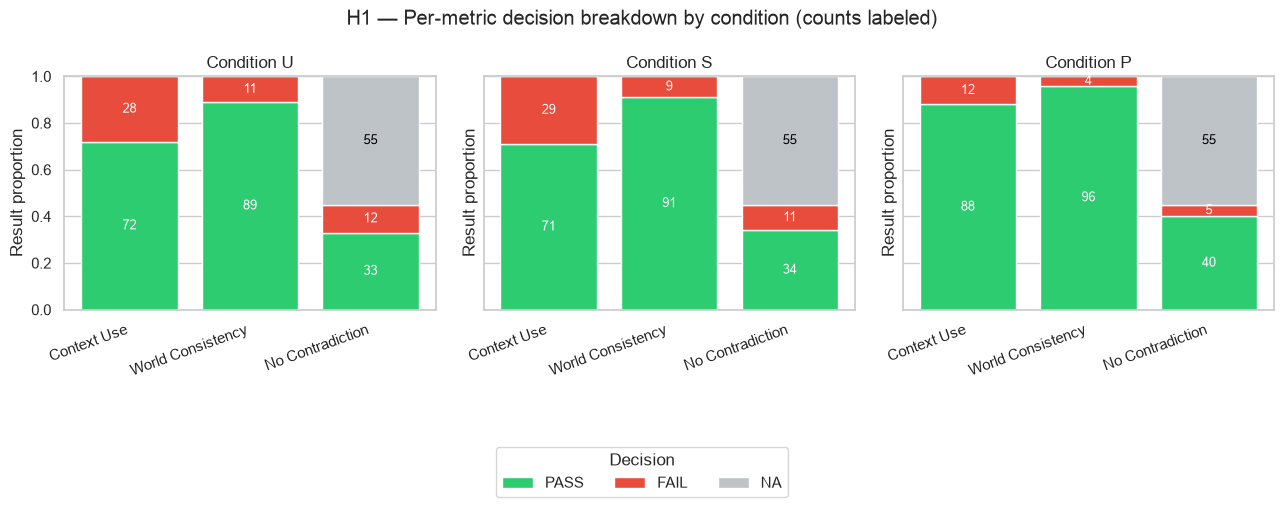

In [49]:
def metric_decision_counts(df, condition):
    condition_df = df[df["context_condition"] == condition]
    counts = pd.DataFrame({
        label: condition_df[column].value_counts().reindex(DECISION_ORDER, fill_value=0)
        for label, column in METRIC_COLUMNS.items()
    }).T
    return counts[DECISION_ORDER]


fig, axes = plt.subplots(1, 3, figsize=(13, 4.5), sharey=True)

for ax, condition in zip(axes, CONDITION_ORDER):
    counts = metric_decision_counts(h1_active, condition)
    proportions = counts.div(counts.sum(axis=1), axis=0)

    bottom = pd.Series(0.0, index=proportions.index)
    for decision in DECISION_ORDER:
        ax.bar(
            proportions.index, proportions[decision], bottom=bottom,
            color=DECISION_COLORS[decision], label=decision,
        )
        for metric in proportions.index:
            height = proportions.loc[metric, decision]
            count = counts.loc[metric, decision]
            if height > 0:
                ax.text(
                    metric, bottom[metric] + height / 2, str(int(count)),
                    ha="center", va="center", fontsize=9,
                    color="black" if decision == "NA" else "white",
                )
        bottom = bottom + proportions[decision]

    ax.set_title(f"Condition {condition}")
    ax.set_ylim(0, 1)
    ax.set_ylabel("Result proportion")
    plt.setp(ax.get_xticklabels(), rotation=20, ha="right")

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, title="Decision", loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.12))
fig.suptitle("H1 — Per-metric decision breakdown by condition (counts labeled)")
plt.tight_layout(rect=[0, 0.12, 1, 1])
plt.show()

The same breakdown from the author's blind human labels in
`data/research_annotations/judge_validation/manual_label/` (`human_labels_<pilot>.csv`, exported from
the `.numbers` sheet of each labelled pilot, with its `blind_key_<pilot>.csv` mapping versions A/B/C back to U/S/P).
Only turns from the generation runs loaded above are shown (pilots 1-5, seed 1). `EXCLUDE` (a `t11` R6 whose R3
gave no specific answer) is shown as NA. Skipped if no labelled pilot matches the loaded runs.

Human-labelled turn-metrics matching the loaded runs: 900


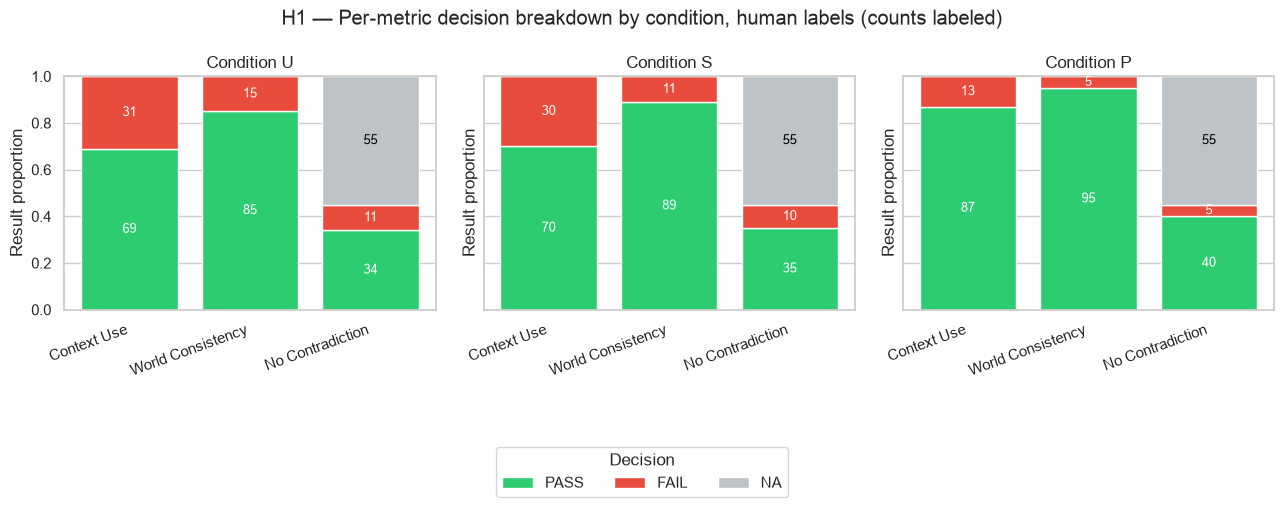

In [50]:
HUMAN_LABEL_DIR = REPO_ROOT / "data" / "research_annotations" / "judge_validation" / "manual_label"
TURN_KEYS = ["generation_run_id", "trial_id", "context_condition", "round"]
LABEL_METRICS = ["context_use", "world_consistency", "no_contradiction"]


def load_blind_labels(label_dir):
    """Long format (one row per turn and metric) from every labelled pilot sheet."""
    frames = []
    for sheet in sorted(label_dir.glob("human_labels_*.csv")):
        key_path = label_dir / sheet.name.replace("human_labels_", "blind_key_")
        if not key_path.exists():
            continue
        # keep_default_na=False keeps the label text "NA" as a label instead of a missing value
        labels = pd.read_csv(sheet, keep_default_na=False)
        if (labels[LABEL_METRICS] == "").any().any():
            print(f"{sheet.name}: not fully labelled yet, skipped")
            continue
        key = pd.read_csv(key_path, keep_default_na=False)
        labels = labels.merge(key, on=["trial_id", "version"])
        frames.append(labels.melt(
            id_vars=TURN_KEYS, value_vars=LABEL_METRICS, var_name="metric", value_name="final_label"
        ))
    if not frames:
        return pd.DataFrame(columns=TURN_KEYS + ["metric", "final_label"])
    combined = pd.concat(frames, ignore_index=True)
    combined["round"] = combined["round"].astype(int)
    combined["label_source"] = "author (blind)"
    return combined[combined["generation_run_id"].isin(set(h1_active["generation_run_id"]))]


human_labels = load_blind_labels(HUMAN_LABEL_DIR)
HAS_HUMAN = not human_labels.empty
print(f"Human-labelled turn-metrics matching the loaded runs: {len(human_labels)}")
if HAS_HUMAN:

    # One row per turn, one column per metric, named like the judge's columns so
    # metric_decision_counts() works on it unchanged.
    h1_human = (
        human_labels.assign(final_label=human_labels["final_label"].replace({"EXCLUDE": "NA"}))
        .pivot_table(index=TURN_KEYS, columns="metric", values="final_label", aggfunc="first")
        .rename(columns={
            "context_use": METRIC_COLUMNS["Context Use"],
            "world_consistency": METRIC_COLUMNS["World Consistency"],
            "no_contradiction": METRIC_COLUMNS["No Contradiction"],
        })
        .reset_index()
    )
    h1_human["context_condition"] = pd.Categorical(h1_human["context_condition"], categories=CONDITION_ORDER, ordered=True)
    for column in METRIC_COLUMNS.values():
        h1_human[column] = pd.Categorical(h1_human[column], categories=DECISION_ORDER, ordered=True)

    fig, axes = plt.subplots(1, 3, figsize=(13, 4.5), sharey=True)
    for ax, condition in zip(axes, CONDITION_ORDER):
        counts = metric_decision_counts(h1_human, condition)
        proportions = counts.div(counts.sum(axis=1), axis=0)
        bottom = pd.Series(0.0, index=proportions.index)
        for decision in DECISION_ORDER:
            ax.bar(proportions.index, proportions[decision], bottom=bottom,
                   color=DECISION_COLORS[decision], label=decision)
            for metric in proportions.index:
                height = proportions.loc[metric, decision]
                count = counts.loc[metric, decision]
                if height > 0:
                    ax.text(metric, bottom[metric] + height / 2, str(int(count)),
                            ha="center", va="center", fontsize=9,
                            color="black" if decision == "NA" else "white")
            bottom = bottom + proportions[decision]
        ax.set_title(f"Condition {condition}")
        ax.set_ylim(0, 1)
        ax.set_ylabel("Result proportion")
        plt.setp(ax.get_xticklabels(), rotation=20, ha="right")

    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, title="Decision", loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.12))
    fig.suptitle("H1 — Per-metric decision breakdown by condition, human labels (counts labeled)")
    plt.tight_layout(rect=[0, 0.12, 1, 1])
    plt.show()
else:
    print('No human labels for the loaded runs: chart skipped.')

### Combined consistency score by condition

The single averaged H1 outcome (`evaluate.py:compute_consistency`, N/A-excluded per turn). Bar
height is the mean; `n=` is how many turns actually had a non-N/A score contributing to it.

In [51]:
h1_summary = (
    h1_active.groupby("context_condition", observed=True)["consistency"]
    .agg(["mean", "count"])
    .rename(columns={"mean": "mean_consistency", "count": "turns_scored"})
    .loc[CONDITION_ORDER]
)
h1_summary

,mean_consistency,turns_scored
context_condition,,
U,0.786667,100
S,0.798333,100
P,0.913333,100


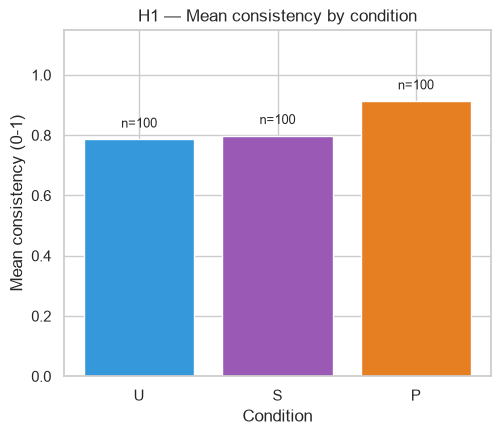

In [52]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
bars = ax.bar(h1_summary.index, h1_summary["mean_consistency"], color=[CONDITION_COLORS[c] for c in CONDITION_ORDER])
ax.set_ylim(0, 1.15)
ax.set_ylabel("Mean consistency (0-1)")
ax.set_xlabel("Condition")
ax.set_title("H1 — Mean consistency by condition")
for bar, n in zip(bars, h1_summary["turns_scored"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.03,
        f"n={int(n)}", ha="center", va="bottom", fontsize=9,
    )
plt.show()

### Consistency by trial type, pilot, and seed

Mean turn consistency per condition. The pilot table is the unit for comparing conditions across
scenes; the seed table shows how much generation sampling moves the result.

In [53]:
def by_condition(df, row, value):
    return (
        df.groupby([row, "context_condition"], observed=True)[value].mean()
        .unstack("context_condition").reindex(columns=CONDITION_ORDER)
    )


display(by_condition(h1_active, "category", "consistency").round(3))
display(by_condition(h1_active, "pilot", "consistency").round(3))
display(by_condition(h1_active, "seed", "consistency").round(3))

context_condition,U,S,P
category,,,
1: neutral (t01-t06),0.983,0.950,0.983
2: stress (t07-t10),0.375,0.500,0.775
3: multi-turn (t11),0.833,0.827,0.927


context_condition,U,S,P
pilot,,,
1,0.833,0.833,0.967
2,0.808,0.783,0.833
3,0.800,0.850,1.000
4,0.700,0.783,0.883
5,0.792,0.742,0.883


context_condition,U,S,P
seed,,,
1,0.787,0.798,0.913


The same score computed from the author's blind human labels loaded above. A turn's score is the mean of its applicable
metrics (PASS = 1, FAIL = 0; NA and EXCLUDE left out), as in `evaluate.py`. The judge
bars use the same turns, so the two are directly comparable.

In [54]:
if HAS_HUMAN:
    scored_labels = human_labels[human_labels["final_label"].isin(["PASS", "FAIL"])]
    human_turns = (
        scored_labels.assign(score=scored_labels["final_label"].eq("PASS").astype(float))
        .groupby(TURN_KEYS, as_index=False)["score"].mean()
        .rename(columns={"score": "human_consistency"})
    )

    judge_turns = h1_active[TURN_KEYS + ["consistency"]].copy()
    judge_turns["context_condition"] = judge_turns["context_condition"].astype(str)
    paired_turns = human_turns.merge(judge_turns, on=TURN_KEYS, how="inner").dropna(subset=["consistency"])

    h1_human_summary = (
        paired_turns.groupby("context_condition")
        .agg(judge_consistency=("consistency", "mean"),
             human_consistency=("human_consistency", "mean"),
             turns_scored=("human_consistency", "size"))
        .loc[CONDITION_ORDER]
    )
    print("Label sources:", human_labels["label_source"].value_counts().to_dict())
    display(h1_human_summary.round(3))
else:
    print('No human labels for the loaded runs: skipped.')

Label sources: {'author (blind)': 900}


,judge_consistency,human_consistency,turns_scored
context_condition,,,
U,0.787,0.753,100
S,0.798,0.785,100
P,0.913,0.902,100


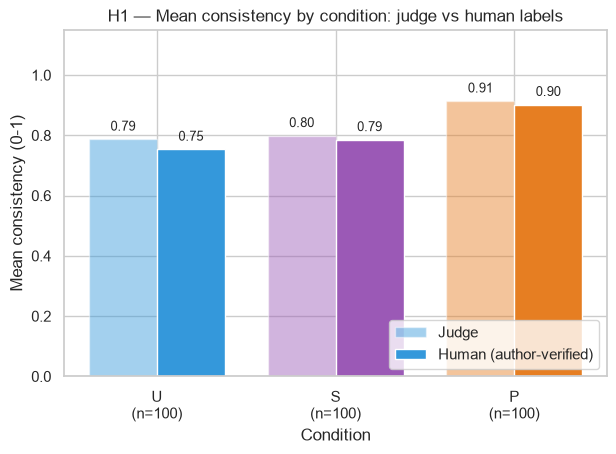

In [55]:
if HAS_HUMAN:
    fig, ax = plt.subplots(figsize=(7, 4.5))
    x = np.arange(len(CONDITION_ORDER))
    width = 0.38
    judge_bars = ax.bar(x - width / 2, h1_human_summary["judge_consistency"], width,
                        color=[CONDITION_COLORS[c] for c in CONDITION_ORDER], alpha=0.45, label="Judge")
    human_bars = ax.bar(x + width / 2, h1_human_summary["human_consistency"], width,
                        color=[CONDITION_COLORS[c] for c in CONDITION_ORDER], label="Human (author-verified)")
    for bars in (judge_bars, human_bars):
        for bar in bars:
            ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.02,
                    f"{bar.get_height():.2f}", ha="center", va="bottom", fontsize=9)
    ax.set_xticks(x, [f"{c}\n(n={int(n)})" for c, n in zip(CONDITION_ORDER, h1_human_summary["turns_scored"])])
    ax.set_ylim(0, 1.15)
    ax.set_ylabel("Mean consistency (0-1)")
    ax.set_xlabel("Condition")
    ax.set_title("H1 — Mean consistency by condition: judge vs human labels")
    ax.legend(loc="lower right")
    plt.show()
else:
    print('No human labels for the loaded runs: chart skipped.')

### Caveats

- Turns from different seeds of the same trial are not independent, nor are turns of the same
  scene; the bars pool them. Compare conditions per pilot (table above) before reading the pooled
  means, and use the statistical tests in the thesis for claims.
- Pilots 1-5 were used to develop the trials and the judge. Set `PILOTS = [6, 7, 8,
  9, 10]` to check that the comparisons hold on the other scenes.
- Check `runs_df` for incomplete runs before reading any chart.

## 2. H2 — Realism

### Per-dimension breakdown

CharacterBox's seven metrics, one grouped bar chart with all three conditions together (unlike
H1's per-condition subplots — there's no 100%-stacking requirement here, so one chart is easier
to compare across conditions). Error bars are standard error across trials. Unlike H1, there's no
N/A here: every trial gets a full 1–5 score on all 7 metrics.

In [56]:
if HAS_H2:
    score_columns = [column for column in h2_active.columns if column.startswith("scores.")]

    dimension_mean = (
        h2_active.groupby("context_condition", observed=True)[score_columns]
        .mean()
        .rename(columns=lambda c: c.replace("scores.", ""))
        .loc[CONDITION_ORDER]
    )
    dimension_sem = (
        h2_active.groupby("context_condition", observed=True)[score_columns]
        .sem()
        .rename(columns=lambda c: c.replace("scores.", ""))
        .loc[CONDITION_ORDER]
    )
    display(dimension_mean)
else:
    print('No H2 results loaded (evaluate.py --h1-only): skipped.')

,Knowledge Accuracy,Emotional Expression,Personality Traits,Behavioral Accuracy,Immersion,Adaptability,Behavioral Coherence
context_condition,,,,,,,
U,3.727273,3.781818,3.927273,3.727273,3.072727,3.127273,2.763636
S,3.981818,3.800000,3.981818,3.872727,3.090909,2.854545,2.618182
P,4.418182,3.745455,3.963636,3.800000,3.236364,3.309091,3.236364


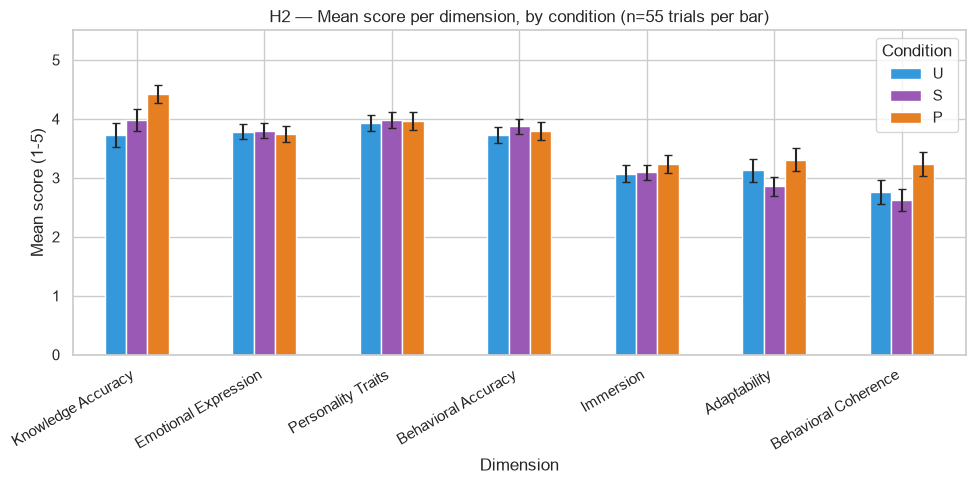

In [57]:
if HAS_H2:
    fig, ax = plt.subplots(figsize=(10, 5))
    dimension_mean.T.plot(
        kind="bar", yerr=dimension_sem.T, ax=ax, capsize=3,
        color=[CONDITION_COLORS[c] for c in CONDITION_ORDER],
    )
    ax.set_ylim(0, 5.5)
    ax.set_ylabel("Mean score (1-5)")
    ax.set_xlabel("Dimension")
    ax.set_title(f"H2 — Mean score per dimension, by condition (n={len(h2_active) // 3} trials per bar)")
    plt.xticks(rotation=30, ha="right")
    plt.legend(title="Condition")
    plt.tight_layout()
    plt.show()
else:
    print('No H2 results loaded (evaluate.py --h1-only): skipped.')

### Combined realism score by condition

The single averaged H2 outcome (`evaluate.py:evaluate_h2_trial`, unweighted mean of the 7
dimensions). Bar height is the mean; error bars are standard error across trials; `n=` is
trials scored (pooled over the loaded seeds and pilots).

In [58]:
if HAS_H2:
    h2_summary = (
        h2_active.groupby("context_condition", observed=True)["average"]
        .agg(["mean", "sem", "count"])
        .rename(columns={"mean": "mean_realism", "sem": "sem_realism", "count": "trials_scored"})
        .loc[CONDITION_ORDER]
    )
    display(h2_summary)
else:
    print('No H2 results loaded (evaluate.py --h1-only): skipped.')

,mean_realism,sem_realism,trials_scored
context_condition,,,
U,3.446753,0.121493,55
S,3.457143,0.106763,55
P,3.672727,0.126188,55


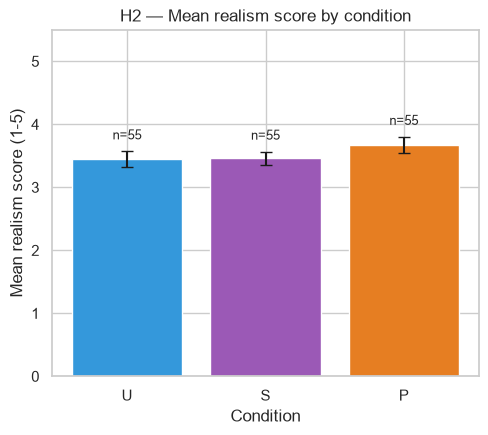

In [59]:
if HAS_H2:
    fig, ax = plt.subplots(figsize=(5.5, 4.5))
    bars = ax.bar(
        h2_summary.index, h2_summary["mean_realism"],
        yerr=h2_summary["sem_realism"], capsize=4,
        color=[CONDITION_COLORS[c] for c in CONDITION_ORDER],
    )
    ax.set_ylim(0, 5.5)
    ax.set_ylabel("Mean realism score (1-5)")
    ax.set_xlabel("Condition")
    ax.set_title("H2 — Mean realism score by condition")
    for bar, (_, row) in zip(bars, h2_summary.iterrows()):
        label_y = row["mean_realism"] + row["sem_realism"] + 0.15
        ax.text(
            bar.get_x() + bar.get_width() / 2, label_y,
            f"n={int(row['trials_scored'])}", ha="center", va="bottom", fontsize=9,
        )
    plt.show()
else:
    print('No H2 results loaded (evaluate.py --h1-only): skipped.')

In [60]:
if HAS_H2:
    display(by_condition(h2_active, "category", "average").round(3))
    display(by_condition(h2_active, "pilot", "average").round(3))
    display(by_condition(h2_active, "seed", "average").round(3))
else:
    print('No H2 results loaded: skipped.')

context_condition,U,S,P
category,,,
1: neutral (t01-t06),3.719,3.743,3.876
2: stress (t07-t10),3.300,3.264,3.621
3: multi-turn (t11),2.400,2.514,2.657


context_condition,U,S,P
pilot,,,
1,3.468,3.571,3.468
2,4.091,3.818,4.325
3,2.571,2.740,2.818
4,3.753,3.727,3.935
5,3.351,3.429,3.818


context_condition,U,S,P
seed,,,
1,3.447,3.457,3.673


### Caveats

- Error bars are standard error across trials, which treats trials from different seeds and
  scenes as independent; they are not a significance test.
- `SEEDS` / `PILOTS` (set in the pre-processing section) apply here too.

## 3. H3 — Multi-turn consistency

The H1 metrics over the 10-round trial (`t11`, trial type 3). Trials are selected by round count,
so other multi-turn trials would be included automatically.

In [61]:
rounds_per_trial = h1_active.groupby("trial_id")["round"].nunique()
multi_turn_trial_ids = rounds_per_trial[rounds_per_trial > 1].index.tolist()

h3_df = h1_active[h1_active["trial_id"].isin(multi_turn_trial_ids)].sort_values(
    ["trial_id", "context_condition", "round"]
)
print("Multi-turn trials found:", multi_turn_trial_ids)

# One t11 per pilot and seed; the curve averages over all of them.
multi_turn_curve = (
    h3_df.groupby(["context_condition", "round"], observed=True)["consistency"]
    .mean()
    .reset_index()
)
multi_turn_curve.head()

Multi-turn trials found: ['cb_hp_012_newt_mcgonagall_t11', 'cb_hp_019_luna_neville_t11', 'cb_hp_031_dumbledore_harry_t11', 'cb_hp_032_harry_seamus_t11', 'cb_hp_044_harry_hagrid_t11']


,context_condition,round,consistency
0,U,1,1.000000
1,U,2,0.933333
2,U,3,1.000000
3,U,4,1.000000
4,U,5,1.000000


### Consistency over time, with both candidate "decline rate" summaries

The line chart is the data; "decline rate" is just a number summarising it, shown two ways
below the chart so you can pick one:

- **Trend-line slope** (dashed lines, and in the legend): a fitted linear slope per condition.
  Precise, but a raw regression coefficient is exactly the kind of number a "don't want to see
  numbers" audience tends to bounce off.
- **Early vs. late half** (table below): mean consistency in rounds 1–5 vs. 6–10. Less
  statistically formal, but reads immediately without translation.

Dotted vertical lines mark rounds 6 and 8, the two misquote rounds of the shared `t11` skeleton
(`docs/trial-design-guide.md`). This is set by hand, since round *type* isn't a structured field;
update it if a multi-turn trial uses different rounds.

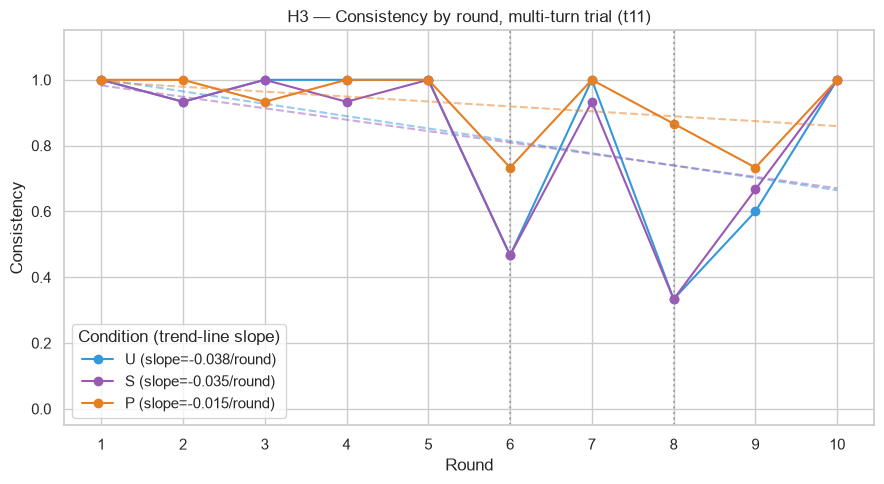

In [62]:
FALSE_PREMISE_ROUNDS = {6, 8}  # misquote rounds of the shared t11 skeleton

slopes = {}
fig, ax = plt.subplots(figsize=(9, 5))

for condition in CONDITION_ORDER:
    subset = multi_turn_curve[multi_turn_curve["context_condition"] == condition].sort_values("round")
    fit_subset = subset.dropna(subset=["consistency"])
    if len(fit_subset) >= 2:
        slope, intercept = np.polyfit(fit_subset["round"], fit_subset["consistency"], 1)
    else:
        slope, intercept = float("nan"), float("nan")
    slopes[condition] = slope

    label = f"{condition} (slope={slope:+.3f}/round)" if slope == slope else condition
    ax.plot(subset["round"], subset["consistency"], marker="o", label=label, color=CONDITION_COLORS[condition])
    if slope == slope:
        trend_y = slope * fit_subset["round"] + intercept
        ax.plot(fit_subset["round"], trend_y, linestyle="--", color=CONDITION_COLORS[condition], alpha=0.5)

for round_number in FALSE_PREMISE_ROUNDS:
    ax.axvline(round_number, color="grey", linestyle=":", alpha=0.6)

ax.set_xticks(range(1, 11))
ax.set_ylim(-0.05, 1.15)
ax.set_xlabel("Round")
ax.set_ylabel("Consistency")
ax.set_title("H3 — Consistency by round, multi-turn trial (t11)")
ax.legend(title="Condition (trend-line slope)")
plt.tight_layout()
plt.show()

In [63]:
EARLY_ROUNDS = range(1, 6)
LATE_ROUNDS = range(6, 11)

early_late = pd.DataFrame({
    "early_mean_r1_5": h3_df[h3_df["round"].isin(EARLY_ROUNDS)]
        .groupby("context_condition", observed=True)["consistency"].mean(),
    "late_mean_r6_10": h3_df[h3_df["round"].isin(LATE_ROUNDS)]
        .groupby("context_condition", observed=True)["consistency"].mean(),
}).loc[CONDITION_ORDER]
early_late["change"] = early_late["late_mean_r6_10"] - early_late["early_mean_r1_5"]
early_late["trend_slope"] = pd.Series(slopes)
early_late

,early_mean_r1_5,late_mean_r6_10,change,trend_slope
context_condition,,,,
U,0.986667,0.680000,-0.306667,-0.037576
S,0.973333,0.680000,-0.293333,-0.034747
P,0.986667,0.866667,-0.120000,-0.014949


### Contradiction summary

Two more of the research contract's named H3 measures — cheap enough to be table cells rather
than separate charts.

In [64]:
NO_CONTRADICTION_COLUMN = "decisions.no_contradiction.decision"


def first_fail_round(df, condition):
    subset = df[(df["context_condition"] == condition) & (df[NO_CONTRADICTION_COLUMN] == "FAIL")]
    return int(subset["round"].min()) if not subset.empty else None


def cumulative_fail_count(df, condition):
    condition_df = df[df["context_condition"] == condition]
    return int((condition_df[NO_CONTRADICTION_COLUMN] == "FAIL").sum())


contradiction_summary = pd.DataFrame({
    "first_fail_round": {c: first_fail_round(h3_df, c) for c in CONDITION_ORDER},
    "cumulative_fail_count": {c: cumulative_fail_count(h3_df, c) for c in CONDITION_ORDER},
}).loc[CONDITION_ORDER]
contradiction_summary

,first_fail_round,cumulative_fail_count
U,6,12
S,6,11
P,6,5


### Caveats

- One 10-round trial per pilot and seed, so each point of the curve averages only a few replies
  per condition.
- The misquote round markers (6, 8) are set by hand for the shared `t11` skeleton.